# 3.1 · Can constrained adaptation retain generality?

[Notebook index](../README.md) · [Experiment 2 results](<../2. Experiment 2/2.4_lgd_results.ipynb>)

Experiment 3 replaces long from-scratch training. Fix 50% credit / 50% generic synthetic data
and compare four methods with the full-CPT-with-decay baseline already trained in Experiment 2.
Both tasks/backbones, three paired main seeds, 10,000 updates. Reuse baselines. Holdout/OOD
never select hyperparameters.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "src" / "visualize").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from src.visualize import figures, style, campaign, continuation, paper_plots as paper, training_plots
from src.experiments import results
style.apply()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 80)
FIGS = figures.FigureSaver("3.1_retention")

## A · Registered interventions
No-decay CPT isolates weight decay. L2-SP anchors weights to the released checkpoint.
DiagScale learns final query scales. Rank-16 Q/V LoRA keeps keys and other backbone weights
frozen. These are multi-table adaptations of methods mostly studied in downstream fine-tuning,
not guaranteed improvements.

WindowsPath('C:/Users/U0152019/PhD Documents/Projects/4. CreditICL/CreditICL/output CreditICL/figures/3.1_retention/01_registered_retention_design.pdf')

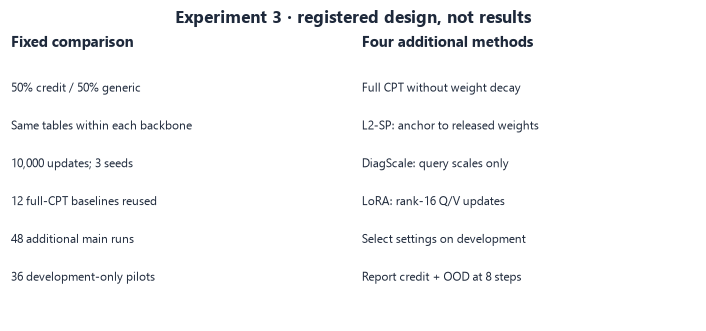

In [2]:
FIGS.save(continuation.design_figure(3), "registered_retention_design",
    caption="Number of runs and retained checkpoints in the 50% credit retention design: four additional methods across both backbones and tasks, three main seeds, 36 development-only pilots and 12 reused full-CPT baselines from Experiment 2.")

## B · Freeze development-only choices
Select the base LR using final 50% Experiment 2 development performance averaged over three
seeds. L2-SP, DiagScale and LoRA each have three pilot candidates, 2,500 updates on the prefix
of the 10,000-update schedule, and pilot seed 991. Report every candidate and its cost. Main
seeds 0/1/2 are separate. Immutable receipts record choices and input hashes; YAML does not change.

In [3]:
from src.experiments.selection import load_selection
BASE_SELECTION = load_selection("retention_pilot", optional=True, for_analysis=True)
print("Base-rate selection:", BASE_SELECTION["choices"] if BASE_SELECTION else "not frozen")
SELECTED = load_selection("retention", optional=True, for_analysis=True)
if SELECTED is not None:
    print("Frozen main choices:", SELECTED["choices"])
    for task in ("pd", "lgd"):
        for backbone in continuation.BACKBONES:
            FIGS.save(continuation.pilot_scores(task, backbone), f"pilots_{task}_{backbone}",
                caption="All three development-only pilot candidates per method after 2,500 updates with seed 991; axes distinguish anchor strength from adapter learning rate. Holdout and OOD scores do not enter selection.")
else:
    print("No frozen adapter selection; main retention results are unavailable.")

Base-rate selection: not frozen
No frozen adapter selection; main retention results are unavailable.


## C · Final credit benefit and OOD retention
Pair each method with the reused Experiment 2 baseline at the selected base LR and the same
training seed. Average folds within datasets before uncertainty over datasets. Previously
exposed holdouts are not pristine confirmation. Trainable parameter counts and tuning costs
differ between methods and remain part of the reported comparison.

In [4]:
if SELECTED is not None:
    for task in ("pd", "lgd"):
        for backbone in continuation.BACKBONES:
            if not results.benchmark_frames(task, 3, final_only=True).empty:
                FIGS.save(continuation.retention_effects(task, backbone), f"final_{task}_{backbone}",
                    caption="Final credit-holdout and native-OOD differences for four methods against their reused full-CPT-with-decay baseline, paired by seed and dataset; intervals are descriptive nominal 95% paired-dataset bootstrap intervals.")

## D · Retention as adaptation proceeds
Eight checkpoints describe credit/OOD trajectories. Keep 10,000 updates as the primary endpoint;
do not select an earlier step from holdout performance. Loss, gradients, hardware and
parameter-drift logs remain available for diagnosis.

In [5]:
if SELECTED is not None:
    for task in ("pd", "lgd"):
        for backbone in continuation.BACKBONES:
            for metric in (("roc_auc", "log_loss", "brier") if task == "pd" else ("r2", "crps")):
                frames = results.benchmark_frames(task, 3)
                if not results.complete_scores(frames, metric, experiment=3).empty:
                    FIGS.save(continuation.checkpoint_curves(task, backbone, experiment=3, metric=metric),
                        f"trajectory_{task}_{backbone}_{metric}",
                        caption="Credit-holdout and native-OOD scores per retained update for four methods and the reused full-CPT baseline; each curve requires three complete seeds, with shading for their mean-score range.")

## Summary
A: interventions; B: frozen choices; C: final contrasts; D: trajectories.

In [6]:
print(continuation.retention_summary())
print(FIGS.summary())

A · REGISTERED DESIGN
Fixed 50% mixture; 48 new 10,000-update runs plus 12 reused Exp2 controls.
B · DEVELOPMENT SELECTION
36 pilots use seed 991 and only development datasets; 2,500 updates on a 10,000-update schedule.
retention_pilot: not frozen
retention: not frozen
C · CREDIT AND OOD RETENTION
Paired final contrasts use the same training seeds and five-fold assignments.
PD / TabICLv2 / credit: final paired results not complete
PD / TabPFN-3 / credit: final paired results not complete
PD / TabICLv2 / ood: final paired results not complete
PD / TabPFN-3 / ood: final paired results not complete
LGD / TabICLv2 / credit: final paired results not complete
LGD / TabPFN-3 / credit: final paired results not complete
LGD / TabICLv2 / ood: final paired results not complete
LGD / TabPFN-3 / ood: final paired results not complete
D · ADAPTATION TRAJECTORIES
Eight retained checkpoints; incomplete seed/fold groups are withheld.
PD / TabICLv2 / credit: no complete three-seed checkpoint groups
PD /